# 3. LGD and EAD models

Builds the loss given default (LGD) and exposure at default (EAD) models.

**Input:** `data/loan_data.pkl`.  
**Output:** LGD and EAD predictions for each defaulted loan.

**3.1 Definitions  
3.2 Load the data  
3.3 Recovery rate  
&nbsp;&nbsp;&nbsp;&nbsp;3.3.1 Distribution  
&nbsp;&nbsp;&nbsp;&nbsp;3.3.2 Choice of model  
3.4 CCF  
&nbsp;&nbsp;&nbsp;&nbsp;3.4.1 Distribution  
&nbsp;&nbsp;&nbsp;&nbsp;3.4.2 Choice of model  
3.5 Train/test split  
3.6 Prepare the inputs  
3.7 LGD model  
3.8 EAD model  
3.9 Save**
## 3.1 Definitions
The expected loss of a loan is given by
$$
EL = PD \times LGD \times EAD,
$$
where $EAD$ is the amount the borrower owes at default, before any recovery, and $LGD$ is the fraction of the $EAD$ that is finally lost, after potential recoveries. Since $PD$ was estimated in notebook 02, we shall estimate $LGD$ and $EAD$. Both models are fitted on the defaulted loans (`default = 1`), for which the loss and the exposure are known, thus we have a target for the model. They are then applied to loans that have not defaulted yet, to estimate the $LGD$ and the $EAD$ that each of them would have if it defaulted.

---

**What the data contains.** A defaulted loan ends when the property or the loan is sold. The loan is then removed from the books of the lender: we call this the *closing* of the loan. For each such loan we have two amounts:

- `zero_balance_removal_upb`: the unpaid principal balance just before the loan was removed, i.e. before any recovery
- `actual_loss`: the loss that remains after all recoveries, costs and unpaid interest,
$$
\texttt{actual\_loss} = \texttt{zero\_balance\_removal\_upb} + \text{net sale proceeds} + \text{delinquent accrued interest} + \text{expenses} + \text{recoveries},
$$
where proceeds and recoveries are negative amounts. A positive `actual_loss` is a loss and a negative one is a gain.

---

**Definitions.** For a loan that defaulted we define
$$
LGD = \frac{\texttt{actual\_loss}}{EAD} = 1 - RR,
$$
where the **recovery rate** $RR$ is the share of the $EAD$ that is recovered.

We also set
$$
EAD = \texttt{zero\_balance\_removal\_upb}
$$
and define the **credit conversion factor** $CCF$ by
$$
CCF = \frac{EAD}{\texttt{orig\_upb}},
$$
where `orig_upb` is the original loan amount. Clearly $EAD = CCF \times \texttt{orig\_upb}$.

The models are fitted on the defaulted loans, with targets $RR$ (LGD model) and $CCF$ (EAD model). We first examine the distributions of the two targets (sections 3.3 and 3.4) and then choose a model suitable for each of them (section 3.5).

---

**Remarks.**
1) Because `actual_loss` includes costs and interest, $LGD$ can be larger than $1$ (loss larger than the balance) or negative (gain), and we have to decide how to treat these values. The loss is not reported for 1,098 defaults, so the LGD model uses 12,986 loans.
2) The $EAD$ is known for all the 14,084 defaulted loans, so the EAD model uses all of them.
3) `zero_balance_removal_upb` is measured at the end of the resolution process and not at the moment of default, which is not in our data. Since a borrower in delinquency does not repay principal, it is reasonable to use it as an approximation of the balance at default, $EAD$.

## 3.2 Load the data

We read `loan_data.pkl` and keep the defaulted loans.

In [1]:
import numpy as np
import pandas as pd

loan_data = pd.read_pickle('../data/loan_data.pkl')
loan_data_defaults = loan_data[loan_data['default'] == 1].copy()
loan_data_defaults.shape

(14084, 31)

## 3.3 Recovery rate

We compute the $EAD$ and the recovery rate $RR = 1 - \frac{\texttt{actual}\_loss}{EAD}$ of each defaulted loan.

### 3.3.1 Distribution

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

In [2]:
loan_data_defaults['EAD'] = loan_data_defaults['zero_balance_removal_upb']
loan_data_defaults['recovery_rate'] = 1 - loan_data_defaults['actual_loss'] / loan_data_defaults['EAD']
loan_data_defaults['recovery_rate'].describe()

count     12986.000000
mean        -50.146181
std        5768.364221
min     -657340.000000
25%           0.269339
50%           0.493591
75%           0.708558
max           2.206142
Name: recovery_rate, dtype: float64

In [4]:
# Count how many loans have recovery_rate <0, =0, in (0,1), =1, >1
rr = loan_data_defaults['recovery_rate']
print((rr < 0).sum(), (rr == 0).sum(), ((rr > 0) & (rr < 1)).sum(), (rr == 1).sum(), (rr > 1).sum())

1035 0 11674 22 255


**Remark.** Before clipping, 1,035 loans (8.0%) have $RR < 0$ (the loss exceeds the $EAD$ because of costs and unpaid interest), none has $RR = 0$, 11,674 (89.9%) have $0 < RR < 1$, 22 have $RR = 1$ and 255 (2.0%) have $RR > 1$ (gain). After clipping to $[0, 1]$, 8.0% of the loans are at $0$, 2.1% at $1$ and 89.9% in the interior.

The recovery rate is a share of the $EAD$, so we clip it to $[0, 1]$: we set $RR = 0$ if $RR < 0$ and $RR = 1$ if $RR > 1$.

In [6]:
loan_data_defaults['recovery_rate'] = np.where(loan_data_defaults['recovery_rate'] < 0, 0, loan_data_defaults['recovery_rate'])
loan_data_defaults['recovery_rate'] = np.where(loan_data_defaults['recovery_rate'] > 1, 1, loan_data_defaults['recovery_rate'])
loan_data_defaults['recovery_rate'].describe()

count    12986.000000
mean         0.487030
std          0.287877
min          0.000000
25%          0.269339
50%          0.493591
75%          0.708558
max          1.000000
Name: recovery_rate, dtype: float64

We plot the histogram of the recovery rate.

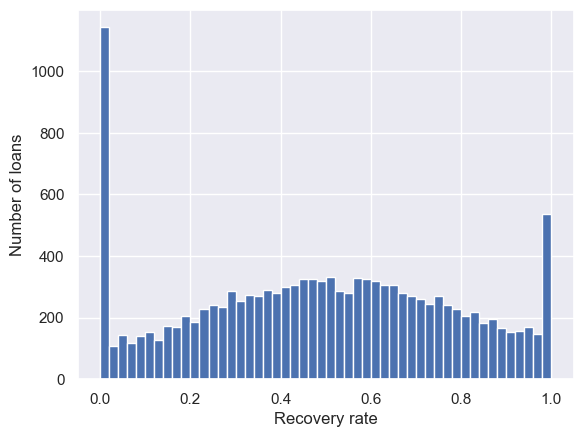

In [9]:
import matplotlib.pyplot as plt

plt.hist(loan_data_defaults['recovery_rate'].dropna(), bins = 50)
plt.xlabel('Recovery rate')
plt.ylabel('Number of loans')
plt.show()

**Remark.** The distribution of $RR$ has three parts: a mass at $0$ (8.0% of the loans, all coming from $RR < 0$), a mass at $1$ (2.1%) and a continuous, unimodal part on $(0, 1)$ with mode near $0.5$, which contains 89.9% of the loans.

### 3.3.2 Choice of model

The distribution of $RR$ has a mass at $0$, a mass at $1$ and a continuous part on $(0, 1)$. We model each part separately:

1. **Logistic regression 1**, on all 12,986 loans: target $1$ if $RR > 0$ and $0$ if $RR = 0$. It gives $\hat p_1 = P(RR > 0)$.
2. **Logistic regression 2**, on the 11,951 loans with $RR > 0$: target $1$ if $RR = 1$ and $0$ if $0 < RR < 1$. It gives $\hat p_2 = P(RR = 1 \mid RR > 0)$.
3. **Beta regression**, on the 11,674 loans with $0 < RR < 1$. The beta distribution is defined on $(0, 1)$, so it respects the range of $RR$ and fits the unimodal shape of the histogram. It gives $\hat\mu = E[RR \mid 0 < RR < 1]$.

For a new loan we apply all three models and combine them by the law of total expectation:
$$
\widehat{RR} = \hat p_1 \left[ \hat p_2 + (1 - \hat p_2)\, \hat\mu \right], \qquad \widehat{LGD} = 1 - \widehat{RR}.
$$
We use the probabilities and not a cut-off, since the expected loss requires the expected value of $RR$.

## 3.4 CCF

### 3.4.1 Distribution

We compute the credit conversion factor $CCF = EAD / \texttt{orig\_upb}$ of each defaulted loan.

In [10]:
loan_data_defaults['CCF'] = loan_data_defaults['EAD'] / loan_data_defaults['orig_upb']
loan_data_defaults['CCF'].describe()

count    1.408400e+04
mean     9.475894e-01
std      7.556471e-02
min      2.380952e-07
25%      9.291630e-01
50%      9.580984e-01
75%      9.784309e-01
max      1.725560e+00
Name: CCF, dtype: float64

In [11]:
ccf = loan_data_defaults['CCF']
print((ccf == 0).sum(), ((ccf > 0) & (ccf < 1)).sum(), (ccf == 1).sum(), (ccf > 1).sum())

0 13168 18 898


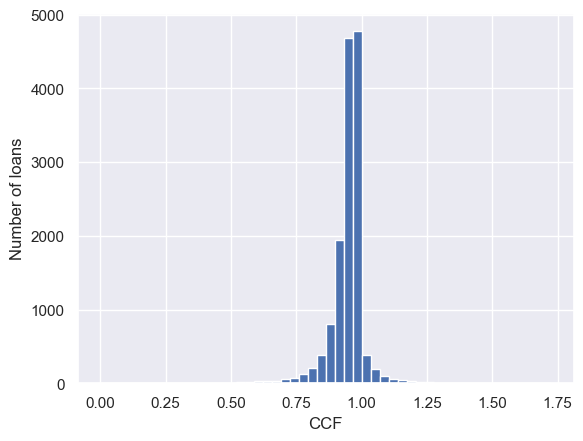

In [30]:
plt.hist(loan_data_defaults['CCF'], bins = 50)
plt.xlabel('CCF')
plt.ylabel('Number of loans')
plt.show()

**Remark.** 13,168 loans (93.5%) have $0 < CCF < 1$, 18 have $CCF = 1$ and 898 (6.4%) have $CCF > 1$. The distribution is unimodal and concentrated just below $1$. The values above $1$ (mostly up to $1.2$) are a smooth continuation of it and not a separate mass: they are loans whose balance increased, e.g. when unpaid amounts were added to the principal. We therefore do not clip the $CCF$, since this would create an artificial mass at $1$ and understate the exposure.

### 3.4.2 Choice of model

The $CCF$ has no mass at a single value and is not bounded above by $1$, so we fit a **linear regression** on all 14,084 defaulted loans, with target $CCF$. For a new loan, $\widehat{EAD} = \widehat{CCF} \times \texttt{orig\_upb}$.

## 3.5 Train/test split

We split the 14,084 defaulted loans once, randomly, into a training set (80%) and a test set (20%). Each model is then fitted on its own subset of the training set, so that all models are evaluated on the same test loans and the combined LGD prediction can be evaluated as a whole. The random seed is fixed, as in notebook 02.


In [31]:
from sklearn.model_selection import train_test_split

loan_data_defaults_train, loan_data_defaults_test = train_test_split(loan_data_defaults, test_size = 0.2, random_state = 42)
print(loan_data_defaults_train.shape, loan_data_defaults_test.shape)

(11267, 34) (2817, 34)


## 3.6 Prepare the inputs

The LGD and EAD models do not need a scorecard, so the continuous variables enter the models directly and only the categorical variables are converted into dummy variables.

| Type | Variables |
|---|---|
| Continuous | `credit_score`, `dti`, `int_rate`, `orig_upb`, `orig_loan_term`, `ltv`, `mi_pct` |
| Categorical | `occupancy_status`, `loan_purpose`, `channel`, `property_type`, `num_borrowers`, `first_time_homebuyer`, `property_state` |

We exclude `cltv` (almost equal to `ltv`), `msa`, `postal_code` and `seller_name` (too many categories), and `num_units`, `prepay_penalty`, `super_conforming` and `harp_indicator` (almost all loans have the same value).

In [32]:
continuous_cols = ['credit_score', 'dti', 'int_rate', 'orig_upb', 'orig_loan_term', 'ltv', 'mi_pct']
categorical_cols = ['occupancy_status', 'loan_purpose', 'channel', 'property_type',
                    'num_borrowers', 'first_time_homebuyer', 'property_state']

In [33]:
loan_data_defaults_train[continuous_cols + categorical_cols].isnull().sum()

credit_score              5
dti                     405
int_rate                  0
orig_upb                  0
orig_loan_term            0
ltv                       0
mi_pct                    0
occupancy_status          0
loan_purpose              0
channel                   0
property_type             0
num_borrowers             0
first_time_homebuyer      0
property_state            0
dtype: int64

Only `credit_score` (5 loans) and `dti` (405 loans, 3.6%) have missing values in the training set. We fill them with the median of the training set, and use the same values for the test set.

In [34]:
for col in ['credit_score', 'dti']:
    median = loan_data_defaults_train[col].median()
    loan_data_defaults_train[col] = loan_data_defaults_train[col].fillna(median)
    loan_data_defaults_test[col] = loan_data_defaults_test[col].fillna(median)

loan_data_defaults_train[['credit_score', 'dti']].isnull().sum(), loan_data_defaults_test[['credit_score', 'dti']].isnull().sum()

(credit_score    0
 dti             0
 dtype: int64,
 credit_score    0
 dti             0
 dtype: int64)

States with fewer than 100 defaulted loans in the training set are merged into one category, `Other`, since their coefficients cannot be estimated reliably. We also measure `orig_upb` in thousands of dollars.

In [35]:
state_counts = loan_data_defaults_train['property_state'].value_counts()
kept_states = state_counts[state_counts >= 100].index

loan_data_defaults_train['property_state'] = np.where(loan_data_defaults_train['property_state'].isin(kept_states), loan_data_defaults_train['property_state'], 'Other')
loan_data_defaults_test['property_state'] = np.where(loan_data_defaults_test['property_state'].isin(kept_states), loan_data_defaults_test['property_state'], 'Other')

loan_data_defaults_train['orig_upb'] = loan_data_defaults_train['orig_upb'] / 1000
loan_data_defaults_test['orig_upb'] = loan_data_defaults_test['orig_upb'] / 1000

print(len(kept_states), (loan_data_defaults_train['property_state'] == 'Other').sum())

28 1043


In [36]:
dummies_train = pd.get_dummies(loan_data_defaults_train[categorical_cols], columns = categorical_cols, prefix_sep = ':', dtype = int)
dummies_test = pd.get_dummies(loan_data_defaults_test[categorical_cols], columns = categorical_cols, prefix_sep = ':', dtype = int)
dummies_test = dummies_test.reindex(columns = dummies_train.columns, fill_value = 0)

print(dummies_train.shape, dummies_test.shape)

(11267, 48) (2817, 48)


The inputs of the models are the continuous variables together with the dummy variables.

In [37]:
inputs_train = pd.concat([loan_data_defaults_train[continuous_cols], dummies_train], axis = 1)
inputs_test = pd.concat([loan_data_defaults_test[continuous_cols], dummies_test], axis = 1)

print(inputs_train.shape, inputs_test.shape)

(11267, 55) (2817, 55)


For each categorical variable, one dummy is left out as the reference category, to avoid perfect multicollinearity with the intercept. We choose the most frequent category in the training set.

In [38]:
ref_categories = []
for col in categorical_cols:
    mode = loan_data_defaults_train[col].mode()[0]
    ref_categories.append(col + ':' + str(mode))

ref_categories

['occupancy_status:P',
 'loan_purpose:C',
 'channel:T',
 'property_type:SF',
 'num_borrowers:1.0',
 'first_time_homebuyer:N',
 'property_state:FL']

We drop the reference categories from the inputs.

In [39]:
inputs_train = inputs_train.drop(ref_categories, axis = 1)
inputs_test = inputs_test.drop(ref_categories, axis = 1)

print(inputs_train.shape, inputs_test.shape)

(11267, 48) (2817, 48)


## 3.7 LGD model

### 3.7.1 Logistic regression 1

Target: `recovery_rate_0_1`, equal to $1$ if $RR > 0$ and $0$ if $RR = 0$. The model is fitted on the training loans with a reported loss.

In [40]:
mask_lgd_train = loan_data_defaults_train['recovery_rate'].notnull()
mask_lgd_test = loan_data_defaults_test['recovery_rate'].notnull()

recovery_rate_0_1_train = np.where(loan_data_defaults_train.loc[mask_lgd_train, 'recovery_rate'] > 0, 1, 0)
recovery_rate_0_1_test = np.where(loan_data_defaults_test.loc[mask_lgd_test, 'recovery_rate'] > 0, 1, 0)

print(mask_lgd_train.sum(), recovery_rate_0_1_train.mean())

10414 0.9194353754561168


We fit the logistic regression with `statsmodels`, which also reports the p-values of the coefficients.

In [41]:
import statsmodels.api as sm

X_lgd_st_1_train = sm.add_constant(inputs_train[mask_lgd_train])
reg_lgd_st_1 = sm.Logit(recovery_rate_0_1_train, X_lgd_st_1_train).fit()
reg_lgd_st_1.summary()

Optimization terminated successfully.
         Current function value: 0.201203
         Iterations 10


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                      y   No. Observations:                10414
Model:                          Logit   Df Residuals:                    10365
Method:                           MLE   Df Model:                           48
Date:                Fri, 13 Nov 2026   Pseudo R-squ.:                  0.2818
Time:                        12:02:28   Log-Likelihood:                -2095.3
converged:                       True   LL-Null:                       -2917.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      2.3937      0.868      2.758      0.006       0.693       4.095
credit_score               0.0023      0.001      3.009      0.003       0.001       0.004
dti                        0.0110      0.003      3.188      0.001       0.004       0.018
int_rate                  -0.4651      0.081     -5.724      0.000      -0.624      -0.306
orig_upb                   0.0123      0.001     15.303      0.000       0.011       0.014
orig_loan_term             0.0009      0.001      0.951      0.342      -0.001       0.003
ltv                       -0.0270      0.005     -5.458      0.000      -0.037      -0.017
mi_pct                     0.0518      0.006      9.351      0.000       0.041       0.063
occupancy_status:I        -0.7907      0.122     -6.499      0.000      -1.029      -0.552
occupancy_status:S        -0.1905      0.222     -0.859      0.391      -0.625       0.244
loan_purpose:N             0.4148      0.112      3.716      0.000       0.196       0.634
loan_purpose:P             0.3229      0.115      2.797      0.005       0.097       0.549
channel:B                 -0.5029      0.201     -2.507      0.012      -0.896      -0.110
channel:C                 -0.2166      0.217     -0.997      0.319      -0.642       0.209
channel:R                  0.1795      0.089      2.007      0.045       0.004       0.355
property_type:CO           0.6032      0.150      4.025      0.000       0.310       0.897
property_type:CP           1.3514      1.137      1.188      0.235      -0.878       3.581
property_type:MH          -0.7608      0.273     -2.787      0.005      -1.296      -0.226
property_type:PU           1.1943      0.259      4.607      0.000       0.686       1.702
num_borrowers:2.0          0.2930      0.091      3.206      0.001       0.114       0.472
first_time_homebuyer:Y     0.2759      0.168      1.640      0.101      -0.054       0.606
property_state:AL          1.2943      0.396      3.264      0.001       0.517       2.071
property_state:AZ          2.1652      0.398      5.439      0.000       1.385       2.945
property_state:CA          2.7995      0.591      4.739      0.000       1.642       3.957
property_state:CO          2.4519      1.021      2.401      0.016       0.450       4.453
property_state:CT         -0.3584      0.351     -1.020      0.308      -1.047       0.330
property_state:GA          1.1438      0.256      4.474      0.000       0.643       1.645
property_state:ID          1.9926      0.738      2.699      0.007       0.545       3.440
property_state:IL         -0.7986      0.155     -5.164      0.000      -1.102      -0.495
property_state:IN          0.3725      0.248      1.502      0.133      -0.114       0.859
property_state:MA          0.6489      0.491      1.323      0.186      -0.313       1.610
property_state:MD          0.0052      0.270      0.019      0.985      -0.524       0.534
property_state:MI         -0.0971      0.160     -0.606 